# Random Forest

## What will you learn in this course? 🧐🧐

Random Forest is one of the best ways to reduce overfitting and to build a powerful, robust algorithm based on decision trees. In this course you'll learn about:

* Interpretation
* Random Forest
    * Bagging Principle
    * Bootstrap
    * Aggregating
* Intuitive understanding 
* Randomness?
* Feature importance
    * Mean decrease Accuracy
    * Mean decrease Gini
    * Variable importance

In [ ]:
import numpy as np
import pandas as pd
from sklearn.ensemble import RandomForestClassifier
from sklearn.inspection import permutation_importance
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
import plotly.io as pio
import plotly.graph_objects as go
pio.templates["course"] = go.layout.Template(layout_colorway=["#3B47C4", "#E4572E", "#2E7D4F", "#F2C14E", "#8E7CC3", "#4BA3C3", "#111111", "#999999"])
pio.templates.default = "plotly_white+course"

## Interpretation

Because the final prediction aggregates many models, the model is hard to interpret directly. However, two methods are used in practice to assess how important each variable is for the prediction (see the Feature importance section below).

## Random Forest 🌲🌲🌲🌲

As its name suggests, a Random Forest is simply a set of decision trees that work together to give better regression or classification results.

### Bagging Principle

Bagging is a contraction of two words: Bootstrap and Aggregating.
The principle of Bagging is very simple. Let $Y$ be the target variable, linked to the explanatory variables $X_1,...,X_p$ by a function $f$ such that $Y=f(X)+\epsilon$, and let $n$ be the number of observations.

### Bootstrap

:::tip Intuition
Picture your dataset as names in a hat. You draw a name, write it down, and put it back in the hat before the next draw. After $n$ draws, some names came out twice or three times and others never came out. Each bootstrap sample is a slightly different copy of the same dataset, and a tree trained on it learns slightly different rules.
:::

Bootstrapping is a process that artificially creates new data samples from an existing one, without changing the distribution of the variables. The principle is simple: we start from a dataset containing $n$ observations and want to create a sample of size $m$. We draw $m$ observations from the original dataset **with replacement**, each observation of the original dataset having a $\frac{1}{n}$ chance of being drawn at each draw (all observations are equally likely). This equiprobability is essential: it ensures that the sample follows the same distribution as the original dataset.

#### See it with data 🔬: what a bootstrap sample looks like

We draw a bootstrap sample of size $m = n = 1{,}000$ from a dataset of 1,000 rows (we only need the row numbers), and count how many times each row was drawn.

In [ ]:
rng = np.random.default_rng(0)
n = 1000
sample = rng.integers(0, n, size=n)          # 1,000 row numbers drawn with replacement
counts = np.bincount(sample, minlength=n)    # how many times each row was drawn

print(f"Rows drawn at least once: {(counts > 0).mean():.1%}")
print(f"Rows never drawn (out-of-bag): {(counts == 0).mean():.1%}")
print(f"Theory for a large n: {1 - np.exp(-1):.1%} drawn, {np.exp(-1):.1%} out-of-bag")
pd.Series(counts).value_counts().sort_index().rename_axis("times drawn").rename("number of rows")

Rows drawn at least once: 62.2%
Rows never drawn (out-of-bag): 37.8%
Theory for a large n: 63.2% drawn, 36.8% out-of-bag


times drawn
0    378
1    356
2    175
3     71
4     19
5      1
Name: number of rows, dtype: int64

**What this shows:** after 1,000 draws with replacement, only 62.2% of the rows were drawn at least once, and 37.8% were never drawn: they are called **out-of-bag** rows. 356 rows were drawn once, 175 twice, 71 three times, and one row even 5 times. This is very close to the theory: for a large $n$, the chance that a row is never drawn is $(1 - 1/n)^n \approx 1/e \approx 36.8\%$. So each tree of a forest sees only about two thirds of the distinct rows, which is why the trees differ.

### Aggregating

:::tip Intuition
Aggregating is the wisdom of the crowd. Ask 100 people to guess the number of sweets in a jar: each guess is off, but the average of the guesses is often surprisingly close, because errors in different directions cancel out. A forest does the same with trees: for regression it averages their predictions, for classification the trees vote.
:::

By drawing $B$ independent samples $\{Z_b\}_{b\in[[1,B]]}$ from the set of observations, we can train $B$ different models. The aggregated prediction of the $B$ models trained on the $B$ samples is written:

* $Y$ quantitative: the aggregated model is the mean of the functions estimated by the models, i.e. the mean of the values of $Y$ predicted for a given observation.

$$
\hat{f}_B(.)=\frac{1}{B}\sum_{b=1}^{B}\hat{f}_{z_b}(.)
$$

* $Y$ qualitative: the aggregated model is the majority vote among the functions estimated by the models, i.e. the modality of $Y$ predicted most often by the different models for a given observation.

$$
\hat{f}_B(.)=\arg\max_{j}\;Card\{b\;|\;\hat{f}_{z_b}(.)=j\}
$$

Bagging: bootstrap samples, one tree per sample, then a vote or an average

The main difficulty of bagging is to build $B$ independent samples. Unless your database contains a very large number of observations, this constraint is hard to respect in most cases.

#### See it with data 🔬: the trees of a forest disagree, the vote decides

The file `bl.txt` describes a balance scale: a weight and a distance on the left arm, a weight and a distance on the right arm (from 1 to 5), and the result: the scale tips to the left (`L`), to the right (`R`), or stays balanced (`B`). We train a forest of 100 trees, then look at what its first 5 trees predict for a few test rows on which they do not all agree.

In [ ]:
balance = pd.read_csv("data/bl.txt")
X = balance.drop(columns="balance")
y = balance["balance"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=0, stratify=y)

forest = RandomForestClassifier(n_estimators=100, random_state=0).fit(X_train, y_train)
# each tree predicts a class number: forest.classes_ turns it back into L / B / R
trees = np.array([forest.classes_[t.predict(X_test.to_numpy()).astype(int)] for t in forest.estimators_])
print("Test accuracy of the first 5 trees, alone:", ", ".join(f"{(p == y_test).mean():.3f}" for p in trees[:5]))
print(f"Test accuracy of the forest (100 trees): {forest.score(X_test, y_test):.3f}")

Test accuracy of the first 5 trees, alone: 0.814, 0.782, 0.798, 0.803, 0.755
Test accuracy of the forest (100 trees): 0.851


In [ ]:
disagree = [i for i in range(len(X_test)) if len(set(trees[:5, i])) > 1][:6]
table = pd.DataFrame(trees[:5, disagree].T, columns=[f"tree {k}" for k in range(1, 6)])
table["share of the 100 trees voting L / B / R"] = [
    " / ".join(f"{(trees[:, i] == c).mean():.0%}" for c in ["L", "B", "R"]) for i in disagree]
table["forest"] = forest.predict(X_test.iloc[disagree])
table["truth"] = y_test.iloc[disagree].to_numpy()
table

,tree 1,tree 2,tree 3,tree 4,tree 5,share of the 100 trees voting L / B / R,forest,truth
0,R,R,R,L,R,31% / 4% / 65%,R,B
1,L,L,R,R,B,30% / 49% / 21%,B,L
2,L,L,L,B,L,81% / 5% / 14%,L,L
3,B,L,R,R,R,10% / 46% / 44%,B,R
4,L,L,R,R,R,11% / 19% / 70%,R,R
5,L,R,L,L,L,67% / 15% / 18%,L,L


**What this shows:** alone, each tree is right on 75.5% to 81.4% of the test rows. They don't make the same mistakes: on the rows above they disagree, sometimes strongly (the second row gets L, R and B votes). The forest of 100 trees follows the majority and reaches 85.1%, better than each of its first 5 trees. These are hard rows, and the forest is still wrong on 3 of these 6: twice when the vote is close (49% vs 30%, and 46% vs 44%), and once on a balanced scale (`B`) that gets only 4% of the votes. Balanced cases are rare in the data (49 of 625 rows), so the trees rarely learn them well. Note: scikit-learn actually averages the class probabilities given by the trees (a "soft" vote), which almost always gives the same answer as counting the votes.

## Intuitive understanding 🤓🤓

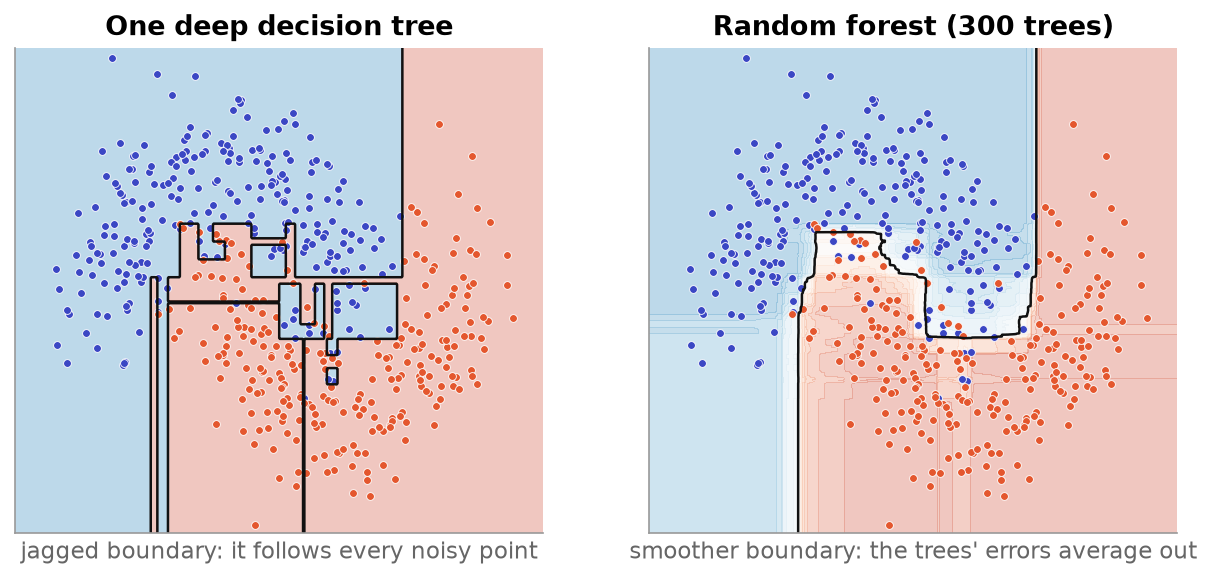

On the same noisy data, a single deep tree draws a jagged boundary that wraps around individual points, while the forest, by averaging many different trees, draws a much smoother one: the errors of the individual trees cancel out.

The first idea behind Random Forest is to apply bagging to several decision trees. The trees built this way can be pruned in several ways:

* Keep the complete trees, possibly with a minimum number of observations in the terminal nodes.
* Keep at most $q$ leaves, or limit the depth of the tree to $q$ node levels.
* Use the approach seen for a single tree, i.e. build the complete tree and then prune it using cross-validation.

In general, the first strategy is used, because it is a good compromise between quality of estimation and amount of computation. Each tree built this way has a very low bias and a large variance. However, aggregating the models reduces this variance. This algorithm is very simple to implement, which is a great advantage. However, the number of models needed before the test error (also called validation error) stabilizes can be very large. The final model also takes a lot of disk space, because the complete structure of every tree must be stored to make predictions. Finally, with so many trees in the model, it becomes difficult, if not impossible, to interpret it the way we could interpret a single tree.

The second idea is to improve bagging so that the trees of the Random Forest are built on data samples that are as "independent" as possible. Randomness is used not only when selecting the observations for each training sample, but also when choosing which explanatory variables can be used: at each split of each tree, only a random subset of the explanatory variables is considered.

This double randomness, in the selection of observations and of explanatory variables, has several advantages: it brings us closer to the hypothesis of independent samples, it reduces the amount of computation needed to build each tree, and it reduces the risk of errors linked to possible correlations between explanatory variables.

One last remark: with $Y$ the target variable and $X_1,...X_p$ the $p$ explanatory variables available, the number of variables usually considered at each split is $\sqrt{p}$ for classification and $\frac{p}{3}$ for regression.

#### See it with data 🔬: more trees, better and more stable

Still on the balance scale. We grow the same forest little by little (`warm_start=True` keeps the trees already built and only adds new ones) and record the test accuracy, compared with a single deep tree.

In [ ]:
single = DecisionTreeClassifier(random_state=0).fit(X_train, y_train).score(X_test, y_test)
growing = RandomForestClassifier(warm_start=True, random_state=0)
sizes, accuracies = [1, 2, 3, 5, 10, 20, 30, 50, 75, 100, 150, 200, 300], []
for b in sizes:
    growing.set_params(n_estimators=b).fit(X_train, y_train)
    accuracies.append(growing.score(X_test, y_test))
print(f"Single tree: {single:.3f}")
print(", ".join(f"{b} trees: {a:.3f}" for b, a in zip(sizes, accuracies)))

fig = go.Figure(go.Scatter(x=sizes, y=accuracies, mode="lines+markers", name="random forest"))
fig.add_hline(y=single, line_dash="dash", line_color="#E4572E", annotation_text="single tree")
fig.update_layout(title="Test accuracy as the forest grows", xaxis_title="number of trees (n_estimators)",
                  yaxis_title="test accuracy", xaxis_type="log")
fig.show()

Single tree: 0.814
1 trees: 0.814, 2 trees: 0.787, 3 trees: 0.835, 5 trees: 0.819, 10 trees: 0.835, 20 trees: 0.846, 30 trees: 0.846, 50 trees: 0.835, 75 trees: 0.846, 100 trees: 0.851, 150 trees: 0.851, 200 trees: 0.840, 300 trees: 0.840


**What this shows:** a forest of 1 tree is just one tree trained on a bootstrap sample (0.814, like the single tree). With very few trees the accuracy jumps up and down (0.787 with 2 trees, 0.835 with 3). From about 20 trees on, it stays between 0.835 and 0.851, above the single tree. Adding trees never makes the forest overfit more: it only makes the result more stable, at the cost of more computation and memory.

## Randomness?

At this point you might ask yourself: how is a random forest random?
It is a fair question, since a decision tree is not random: it is entirely deterministic by construction. The randomness in random forests first comes from the bootstrap. The bootstrap generates a collection of slightly different training sets, which produce different models. A second source of randomness is what we call bootstrap on the columns: in random forests, not all the explanatory variables are used at each split. A good practice is actually to randomly select a subset of variables, to build a forest whose trees are all the more diverse. On top of that, randomly selecting the variables lets all the explanatory variables contribute to the final prediction, which is not necessarily the case for a single decision tree.

#### See it with data 🔬: the column randomness (`max_features`) and the out-of-bag score

The balance data has 4 explanatory variables. With `max_features=4`, every split may look at every variable: this is plain bagging. With `max_features=1`, each split gets one variable drawn at random. For each setting we measure how often two trees of the forest give the same prediction, the test accuracy, and the **out-of-bag (OOB) score**: each row is predicted only by the trees that did not see it in their bootstrap sample (about 37% of them, as we saw above), which gives a free validation score without a test set.

In [ ]:
rows = []
for k in [1, 2, 3, 4]:
    rf_k = RandomForestClassifier(n_estimators=200, max_features=k, oob_score=True, random_state=0).fit(X_train, y_train)
    preds = np.array([t.predict(X_test.to_numpy()) for t in rf_k.estimators_[:50]])
    agreement = np.mean([(preds[i] == preds[j]).mean() for i in range(50) for j in range(i + 1, 50)])
    rows.append({"max_features": k, "agreement between two trees": round(agreement, 3),
                 "OOB score": round(rf_k.oob_score_, 3), "test accuracy": round(rf_k.score(X_test, y_test), 3)})
pd.DataFrame(rows)

,max_features,agreement between two trees,OOB score,test accuracy
0,1,0.741,0.851,0.851
1,2,0.772,0.842,0.840
2,3,0.787,0.833,0.846
3,4,0.792,0.828,0.830


**What this shows:** the fewer variables each split may look at, the more the trees differ: two trees agree on 74.1% of the test rows with `max_features=1`, against 79.2% with `max_features=4` (plain bagging). More diverse trees make a better team here: test accuracy 0.851 with 1 variable, 0.830 with all 4. The OOB score (0.851, 0.842, 0.833, 0.828) follows the same trend as the test accuracy without needing a test set: it is a handy way to tune a forest when data is scarce (`oob_score=True`). For this dataset scikit-learn's default, `"sqrt"`, means $\sqrt{4} = 2$ variables per split.

## Feature importance 📊📊

### Mean decrease Accuracy

:::tip Intuition
Shuffling a column is like scrambling one instrument on a dashboard: the values are still realistic, but they no longer match the rest of the row. If the model relied on that instrument, its error goes up a lot; if it ignored it, nothing changes.
:::

This method consists in randomly shuffling (permuting) the values of one explanatory variable. We then measure the difference between the validation error before and after the shuffle. The larger the increase in validation error after the shuffle, the more important the variable is considered to be for predicting the target variable.

### Mean decrease Gini

This method evaluates the importance of a variable node by node: at each node where the variable is used for the split, it measures the decrease of the heterogeneity function produced by this split. The overall importance of the variable is then the sum of these decreases in heterogeneity, weighted by the number of observations in each node.

### Variable importance

A very useful perk of decision trees and random forests is that they can quantify variable importance. Unlike the F-test or Chi2 scores used for feature selection, the variable importance measured by decision trees and random forests can capture non-linear dependencies between the explanatory variables and the target variable.

Variable importance is calculated as follows. First, the importance of each variable is set to zero. Then, every time a variable is selected to make a division, the resulting reduction in heterogeneity is added to this variable's importance. For a decision tree, the importance of a variable is the sum of its contributions to the construction of the tree. For a Random Forest, the importance of a variable is the average of its importances over all the trees.

#### See it with data 🔬: impurity importance vs permutation importance

We add to the balance data a column of pure random noise, which has nothing to do with the target, and compare the two importance measures: the mean decrease in Gini (`feature_importances_`) and the mean decrease in accuracy, computed by shuffling each column of the **test set** 10 times (`permutation_importance`).

In [ ]:
rng = np.random.default_rng(0)
X_noise = X.assign(noise=rng.normal(size=len(X)))      # a useless, continuous column
Xn_train, Xn_test, yn_train, yn_test = train_test_split(X_noise, y, test_size=0.3, random_state=0, stratify=y)
rf_noise = RandomForestClassifier(n_estimators=200, random_state=0).fit(Xn_train, yn_train)

perm = permutation_importance(rf_noise, Xn_test, yn_test, n_repeats=10, random_state=0)
importances = pd.DataFrame({"mean decrease Gini": rf_noise.feature_importances_,
                            "mean decrease accuracy (permutation)": perm.importances_mean},
                           index=X_noise.columns).round(3)
importances

,mean decrease Gini,mean decrease accuracy (permutation)
left_weight,0.196,0.185
left_distance,0.213,0.148
right_weight,0.208,0.169
right_distance,0.208,0.157
noise,0.176,0.011


In [ ]:
fig = go.Figure([go.Bar(x=importances.index, y=importances[col], name=col) for col in importances.columns])
fig.update_layout(title="Two ways to measure feature importance", xaxis_title="feature",
                  yaxis_title="importance", barmode="group")
fig.show()

**What this shows:** the mean decrease in Gini gives the pure-noise column an importance of 0.176, almost as much as the real variables (0.196 to 0.213). Why? The noise column has hundreds of different values, so deep trees can always find a threshold on it that separates a few training rows by chance. The permutation importance, measured on the test set, is not fooled: shuffling the noise column barely changes the accuracy (0.011), while shuffling a real variable costs between 0.148 and 0.185 of accuracy. Prefer the permutation importance, on a test set, when you want to know what the model really uses.